In [59]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
!pip install seaborn
import tensorflow as tf
from tensorflow import keras
import matplotlib.pyplot as plt
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

In [60]:
dataset_path = "/kaggle/input/competitions/rsna-knee-abnormality-detection"

print("Dataset contents:")
for item in os.listdir(dataset_path):
    print(" -", item)

train = pd.read_csv(f"{dataset_path}/train.csv")
train_series = pd.read_csv(f"{dataset_path}/train_series.csv")
test = pd.read_csv(f"{dataset_path}/test.csv")
test_series = pd.read_csv(f"{dataset_path}/test_series.csv")
sample_submission = pd.read_csv(f"{dataset_path}/sample_submission.csv")

Dataset contents:
 - test_series.csv
 - train_series.csv
 - sample_submission.csv
 - test_series
 - train_series
 - train.csv
 - test.csv


In [61]:
print(train_series.shape)
print(test_series.shape)
print(train.shape)
print(test.shape)
print(sample_submission.shape)


(24371, 5)
(15, 5)
(4407, 14)
(3, 1)
(3, 13)


In [62]:
print("\n train_series")
print(train_series.head())

print("\n test_series")
print(test_series.head())

print("\n train")
print(train.head())

print("\n test")
print(test.head())

print("\n sample_submission")
print(sample_submission.head())


 train_series
                                    StudyInstanceUID  \
0  1.2.826.0.1.3680043.8.498.10004873229099053869...   
1  1.2.826.0.1.3680043.8.498.10004873229099053869...   
2  1.2.826.0.1.3680043.8.498.10004873229099053869...   
3  1.2.826.0.1.3680043.8.498.10004873229099053869...   
4  1.2.826.0.1.3680043.8.498.10004873229099053869...   

                                   SeriesInstanceUID  Fluid_Sensitive  \
0  1.2.826.0.1.3680043.8.498.12343110195036213483...                1   
1  1.2.826.0.1.3680043.8.498.13821229744997220641...                1   
2  1.2.826.0.1.3680043.8.498.23084836536722595275...                0   
3  1.2.826.0.1.3680043.8.498.40734206102458723096...                1   
4  1.2.826.0.1.3680043.8.498.75714899997203615784...                0   

   Fat_Suppression Anatomical_Plane  
0                1         Sagittal  
1                1            Axial  
2                0          Coronal  
3                1          Coronal  
4                0 

In [63]:
study_id = train["StudyInstanceUID"].iloc[0]

print("Study ID:")
print(study_id)

Study ID:
1.2.826.0.1.3680043.8.498.10004873229099053869093324292195817260


In [64]:
study_series = train_series[
    train_series["StudyInstanceUID"] == study_id
]

display(study_series)

,StudyInstanceUID,SeriesInstanceUID,Fluid_Sensitive,Fat_Suppression,Anatomical_Plane
0,1.2.826.0.1.3680043.8.498.10004873229099053869...,1.2.826.0.1.3680043.8.498.12343110195036213483...,1,1,Sagittal
1,1.2.826.0.1.3680043.8.498.10004873229099053869...,1.2.826.0.1.3680043.8.498.13821229744997220641...,1,1,Axial
2,1.2.826.0.1.3680043.8.498.10004873229099053869...,1.2.826.0.1.3680043.8.498.23084836536722595275...,0,0,Coronal
3,1.2.826.0.1.3680043.8.498.10004873229099053869...,1.2.826.0.1.3680043.8.498.40734206102458723096...,1,1,Coronal
4,1.2.826.0.1.3680043.8.498.10004873229099053869...,1.2.826.0.1.3680043.8.498.75714899997203615784...,0,0,Sagittal


In [65]:
print("Number of series:", len(study_series))

Number of series: 5


In [66]:
series_id = study_series["SeriesInstanceUID"].iloc[0]

print("Series ID:")
print(series_id)

Series ID:
1.2.826.0.1.3680043.8.498.12343110195036213483454091715412333772


In [67]:
series_path = os.path.join(
    dataset_path,
    "train_series",
    study_id,
    series_id
)

dcm_files = os.listdir(series_path)

print("Series path:")
print(series_path)

print("Number of DICOM slices:", len(dcm_files))
print("First 5 files:", dcm_files[:5])

Series path:
/kaggle/input/competitions/rsna-knee-abnormality-detection/train_series/1.2.826.0.1.3680043.8.498.10004873229099053869093324292195817260/1.2.826.0.1.3680043.8.498.12343110195036213483454091715412333772
Number of DICOM slices: 22
First 5 files: ['1.2.826.0.1.3680043.8.498.10374285052733466977592225981851620435.dcm', '1.2.826.0.1.3680043.8.498.11560456494251875828657453454342564666.dcm', '1.2.826.0.1.3680043.8.498.62696444312933722854177245172284641767.dcm', '1.2.826.0.1.3680043.8.498.13270416360166070027275555170852805514.dcm', '1.2.826.0.1.3680043.8.498.16282623942824367613229214931863706593.dcm']


In [68]:
import pydicom
middle_index = len(dcm_files) // 2
dcm_path = os.path.join(series_path, dcm_files[middle_index])

ds = pydicom.dcmread(dcm_path)

print("DICOM file:", dcm_files[middle_index])
print("Image shape:", ds.pixel_array.shape)
print("Data type:", ds.pixel_array.dtype)

DICOM file: 1.2.826.0.1.3680043.8.498.42673944844785294518943020113657253754.dcm
Image shape: (512, 512)
Data type: uint16


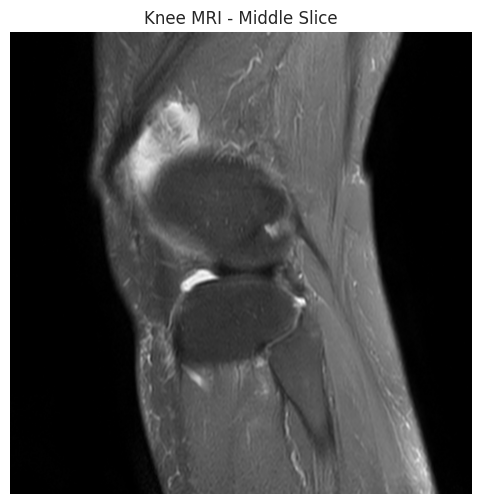

In [69]:
plt.figure(figsize=(6, 6))

plt.imshow(ds.pixel_array, cmap="gray")

plt.title("Knee MRI - Middle Slice")
plt.axis("off")

plt.show()

In [70]:
def load_sorted_series(series_path):
    files = [
        os.path.join(series_path, f)
        for f in os.listdir(series_path)
        if f.endswith(".dcm")
    ]
    slices = [pydicom.dcmread(f) for f in files]
    orientation = np.array(slices[0].ImageOrientationPatient, dtype=float)

    row_direction = orientation[:3]
    column_direction = orientation[3:]

    slice_direction = np.cross(row_direction, column_direction)

    positions = []

    for ds in slices:
        position = np.array(ds.ImagePositionPatient, dtype=float)
        distance = np.dot(position, slice_direction)
        positions.append(distance)

    sorted_slices = [
        ds for _, ds in sorted(zip(positions, slices))
    ]

    return sorted_slices

In [71]:
sorted_slices = load_sorted_series(series_path)

print("Number of slices:", len(sorted_slices))

for i, ds in enumerate(sorted_slices[:5]):
    print(
        f"Slice {i+1}:",
        "InstanceNumber =", getattr(ds, "InstanceNumber", "N/A"),
        "Position =", ds.ImagePositionPatient
    )

Number of slices: 22
Slice 1: InstanceNumber = 1 Position = [-62.468685312953, -142.52268380745, 99.6359090936094]
Slice 2: InstanceNumber = 2 Position = [-67.092823191371, -142.67186898811, 99.3636179101377]
Slice 3: InstanceNumber = 3 Position = [-71.716968699183, -142.82105798347, 99.0913248193174]
Slice 4: InstanceNumber = 4 Position = [-76.341106577601, -142.97024316414, 98.8190336358457]
Slice 5: InstanceNumber = 5 Position = [-80.965252085414, -143.1194283448, 98.5467405450254]


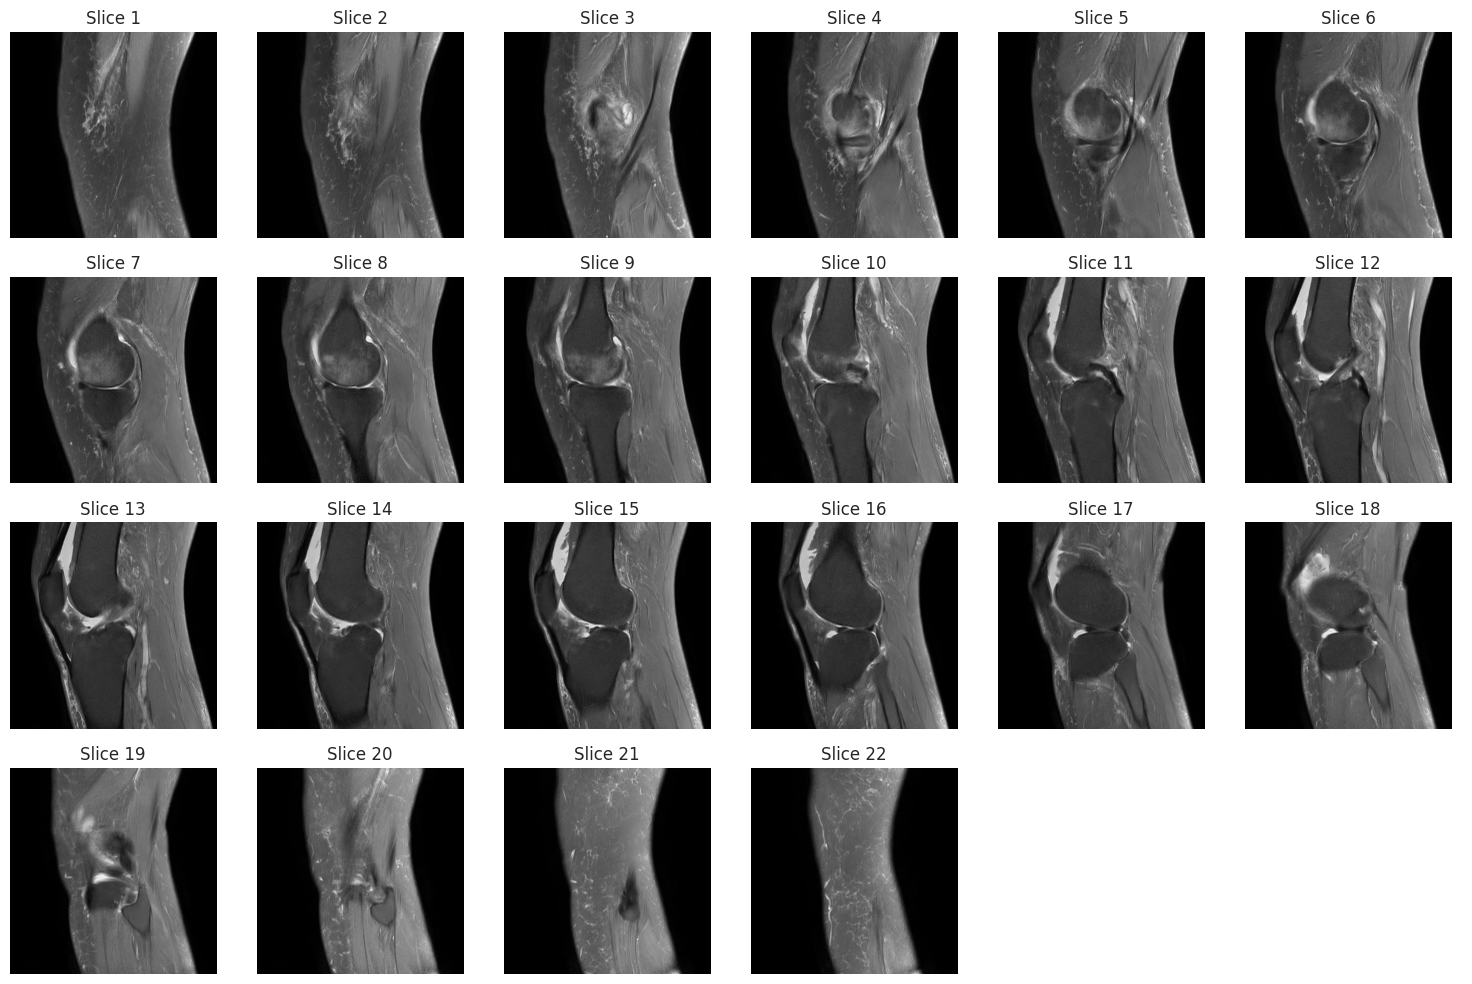

In [72]:
fig, axes = plt.subplots(4, 6, figsize=(15, 10))

for i, ax in enumerate(axes.flat):
    if i < len(sorted_slices):
        ax.imshow(sorted_slices[i].pixel_array, cmap="gray")
        ax.set_title(f"Slice {i + 1}")

    ax.axis("off")
import numpy as np
import matplotlib.pyplot as plt

def normalize_slice(ds):
    image = ds.pixel_array.astype(np.float32)

    # Apply DICOM rescaling if available
    slope = float(getattr(ds, "RescaleSlope", 1))
    intercept = float(getattr(ds, "RescaleIntercept", 0))

    image = image * slope + intercept

    # Normalize to 0-1
    min_value = image.min()
    max_value = image.max()

    if max_value > min_value:
        image = (image - min_value) / (max_value - min_value)
    else:
        image = np.zeros_like(image)

    return image
plt.tight_layout()
plt.show()

In [73]:
def normalize_slice(ds):
    image = ds.pixel_array.astype(np.float32)

    slope = float(getattr(ds, "RescaleSlope", 1))
    intercept = float(getattr(ds, "RescaleIntercept", 0))

    image = image * slope + intercept

    min_value = image.min()
    max_value = image.max()

    if max_value > min_value:
        image = (image - min_value) / (max_value - min_value)
    else:
        image = np.zeros_like(image)

    return image

In [74]:
middle_slice = sorted_slices[len(sorted_slices) // 2]

image = normalize_slice(middle_slice)

print("Shape:", image.shape)
print("Data type:", image.dtype)
print("Minimum:", image.min())
print("Maximum:", image.max())

Shape: (512, 512)
Data type: float32
Minimum: 0.0
Maximum: 1.0


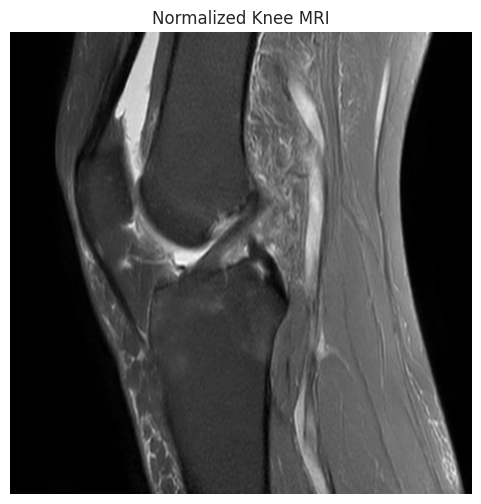

In [75]:
plt.figure(figsize=(6, 6))

plt.imshow(image, cmap="gray", vmin=0, vmax=1)

plt.title("Normalized Knee MRI")
plt.axis("off")

plt.show()

In [76]:
from PIL import Image
def resize_slice(image, size=(224, 224)):
    image_uint8 = (image * 255).astype(np.uint8)

    resized = Image.fromarray(image_uint8).resize(
        size,
        Image.Resampling.BILINEAR
    )

    return np.array(resized).astype(np.float32) / 255.0

In [77]:
resized_image = resize_slice(image)

print("Original shape:", image.shape)
print("Resized shape:", resized_image.shape)
print("Minimum:", resized_image.min())
print("Maximum:", resized_image.max())

Original shape: (512, 512)
Resized shape: (224, 224)
Minimum: 0.0
Maximum: 0.9607843


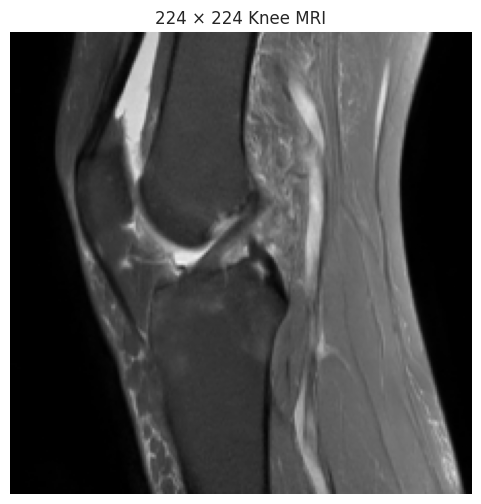

In [78]:
plt.figure(figsize=(6, 6))

plt.imshow(resized_image, cmap="gray", vmin=0, vmax=1)

plt.title("224 × 224 Knee MRI")
plt.axis("off")

plt.show()

In [79]:
from PIL import Image

def process_series(series_path, num_slices=8, image_size=(224, 224)):
    # Get DICOM files
    files = [
        os.path.join(series_path, f)
        for f in os.listdir(series_path)
        if f.endswith(".dcm")
    ]

    # Read DICOM files
    slices = [pydicom.dcmread(f) for f in files]

    # Get slice direction
    orientation = np.array(
        slices[0].ImageOrientationPatient,
        dtype=float
    )

    row_direction = orientation[:3]
    column_direction = orientation[3:]

    slice_direction = np.cross(
        row_direction,
        column_direction
    )

    # Sort using physical position
    positions = []

    for ds in slices:
        position = np.array(
            ds.ImagePositionPatient,
            dtype=float
        )

        distance = np.dot(
            position,
            slice_direction
        )

        positions.append(distance)

    slices = [
        ds for _, ds in sorted(
            zip(positions, slices)
        )
    ]

    # Select evenly spaced slices
    if len(slices) > num_slices:
        indices = np.linspace(
            0,
            len(slices) - 1,
            num_slices
        ).astype(int)

        slices = [slices[i] for i in indices]

    # Process images
    processed = []

    for ds in slices:

        image = ds.pixel_array.astype(np.float32)

        slope = float(
            getattr(ds, "RescaleSlope", 1)
        )

        intercept = float(
            getattr(ds, "RescaleIntercept", 0)
        )

        image = image * slope + intercept

        # Normalize
        min_value = image.min()
        max_value = image.max()

        if max_value > min_value:
            image = (
                image - min_value
            ) / (max_value - min_value)
        else:
            image = np.zeros_like(image)

        # Resize
        image = (
            Image.fromarray(
                (image * 255).astype(np.uint8)
            )
            .resize(
                image_size,
                Image.Resampling.BILINEAR
            )
        )

        image = (
            np.array(image)
            .astype(np.float32) / 255.0
        )

        processed.append(image)

    return np.array(processed)

In [80]:
processed_series = process_series(
    series_path,
    num_slices=8
)

print("Processed shape:", processed_series.shape)
print("Minimum:", processed_series.min())
print("Maximum:", processed_series.max())

Processed shape: (8, 224, 224)
Minimum: 0.0
Maximum: 0.9411765


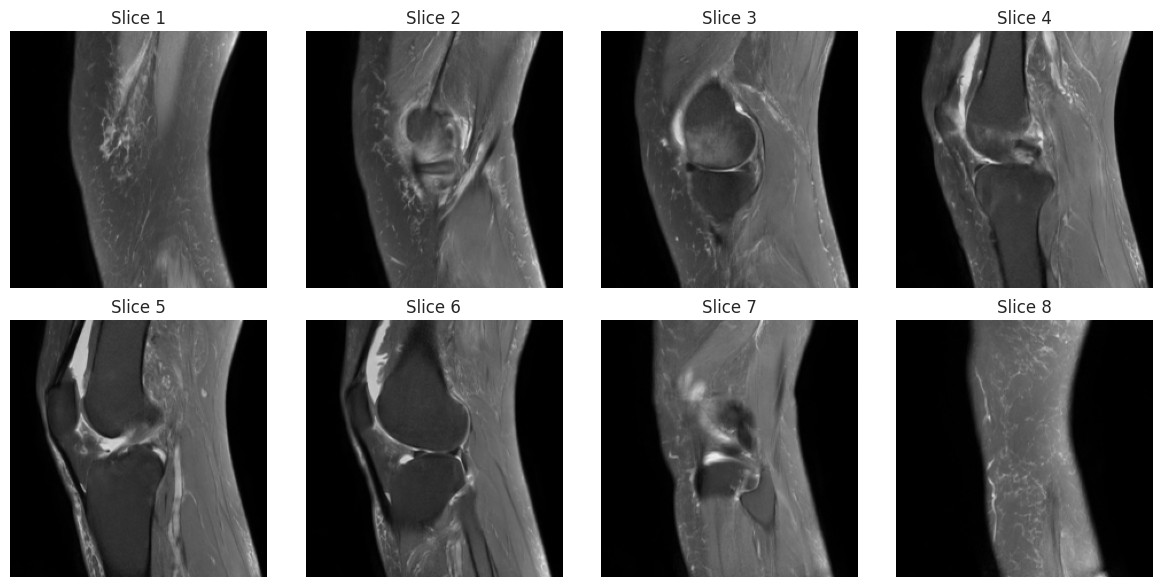

In [81]:
fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for i, ax in enumerate(axes.flat):
    ax.imshow(
        processed_series[i],
        cmap="gray",
        vmin=0,
        vmax=1
    )
    ax.set_title(f"Slice {i + 1}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [82]:
def process_study(study_id, split="train", num_slices=8):

    if split == "train":
        series_info = train_series
    elif split == "test":
        series_info = test_series
    else:
        raise ValueError("split must be 'train' or 'test'")


    study_series = series_info[
        series_info["StudyInstanceUID"] == study_id
    ]

    if study_series.empty:
        raise ValueError(f"No series found for study: {study_id}")

    all_series = []


    for _, row in study_series.iterrows():

        series_id = row["SeriesInstanceUID"]

        series_path = os.path.join(
            dataset_path,
            f"{split}_series",
            study_id,
            series_id
        )

        processed = process_series(
            series_path,
            num_slices=num_slices
        )

        all_series.append(processed)

    return np.array(all_series)

In [83]:
study_data = process_study(
    study_id,
    num_slices=8
)

print("Study shape:", study_data.shape)


Study shape: (5, 8, 224, 224)


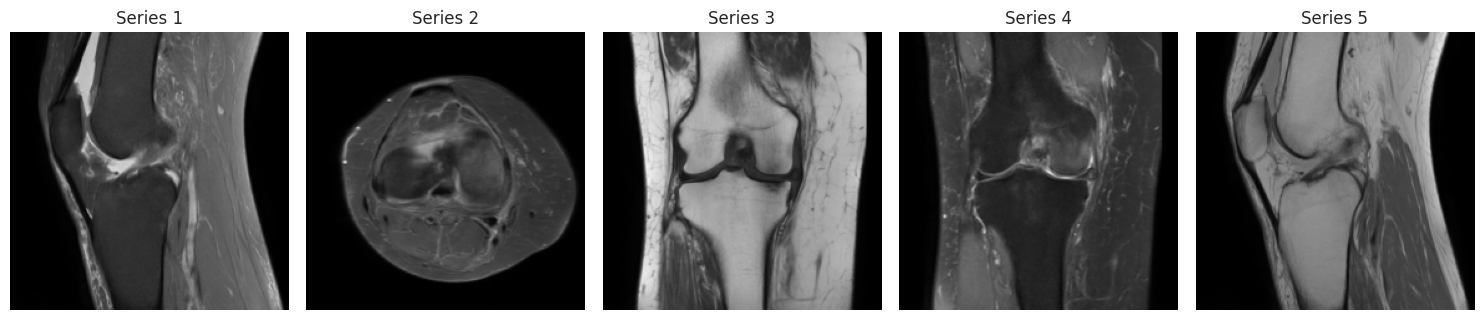

In [84]:
fig, axes = plt.subplots(1, 5, figsize=(15, 4))

for i, ax in enumerate(axes):

    ax.imshow(
        study_data[i, 4],
        cmap="gray",
        vmin=0,
        vmax=1
    )

    ax.set_title(f"Series {i + 1}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [85]:
DATA_DIR = "/kaggle/input/competitions/rsna-knee-abnormality-detection"

train_df = pd.read_csv(f"{DATA_DIR}/train.csv")
test_df = pd.read_csv(f"{DATA_DIR}/test.csv")

train_series_df = pd.read_csv(f"{DATA_DIR}/train_series.csv")
test_series_df = pd.read_csv(f"{DATA_DIR}/test_series.csv")

submission_df = pd.read_csv(f"{DATA_DIR}/sample_submission.csv")

In [86]:
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

In [87]:
target_columns = [
    "ACL", "MCL", "Medial Meniscus", "Lateral Meniscus",
    "Medial OA", "Lateral OA", "PF OA", "Effusion",
    "Synovitis", "Baker's", "Contusion", "Fracture"
]

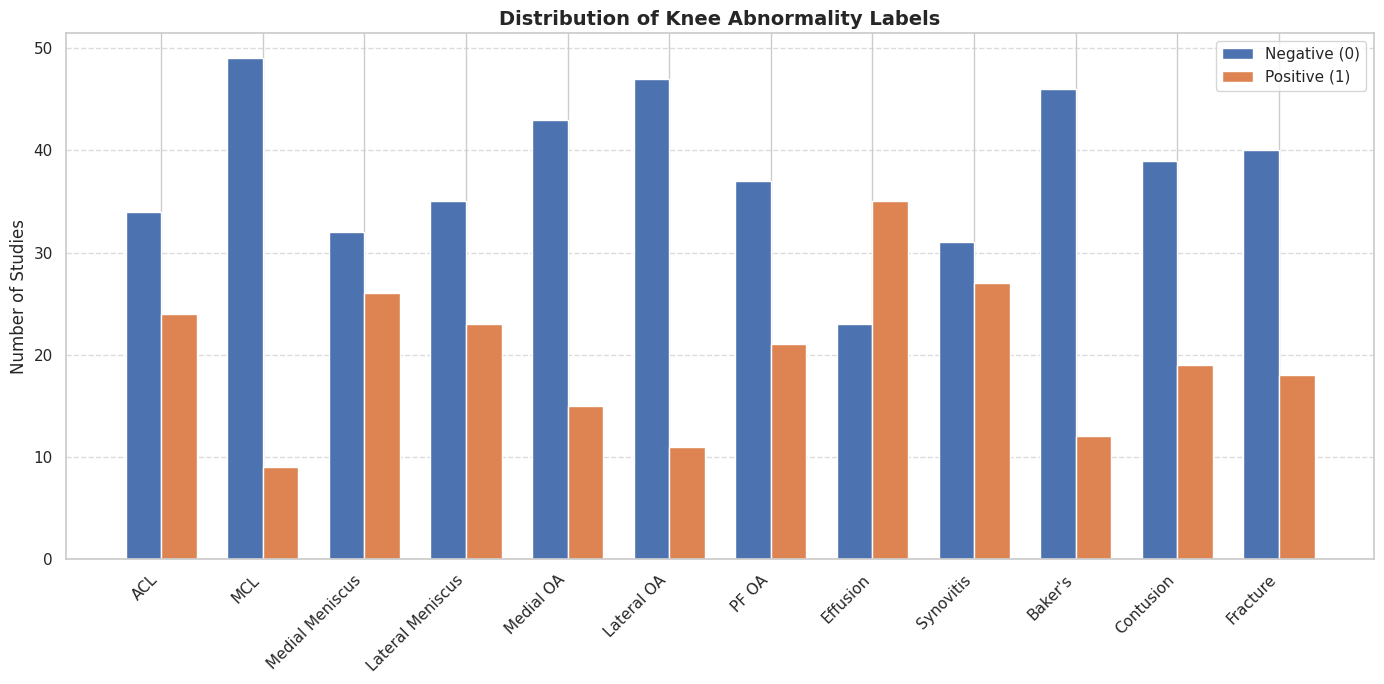

In [88]:
labeled_df = train_df.dropna(subset=target_columns).copy()

positive_counts = labeled_df[target_columns].sum()
negative_counts = len(labeled_df) - positive_counts

x = np.arange(len(target_columns))
width = 0.35

fig, ax = plt.subplots(figsize=(14, 7))

ax.bar(
    x - width/2,
    negative_counts,
    width,
    label='Negative (0)',
    color='#4c72b0'
)

ax.bar(
    x + width/2,
    positive_counts,
    width,
    label='Positive (1)',
    color='#dd8452'
)

ax.set_ylabel('Number of Studies')
ax.set_title(
    'Distribution of Knee Abnormality Labels',
    fontsize=14,
    fontweight='bold'
)

ax.set_xticks(x)
ax.set_xticklabels(target_columns, rotation=45, ha='right')

ax.legend()
ax.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()

plt.savefig('abnormality_label_distribution.png', dpi=300, bbox_inches='tight')

plt.show()

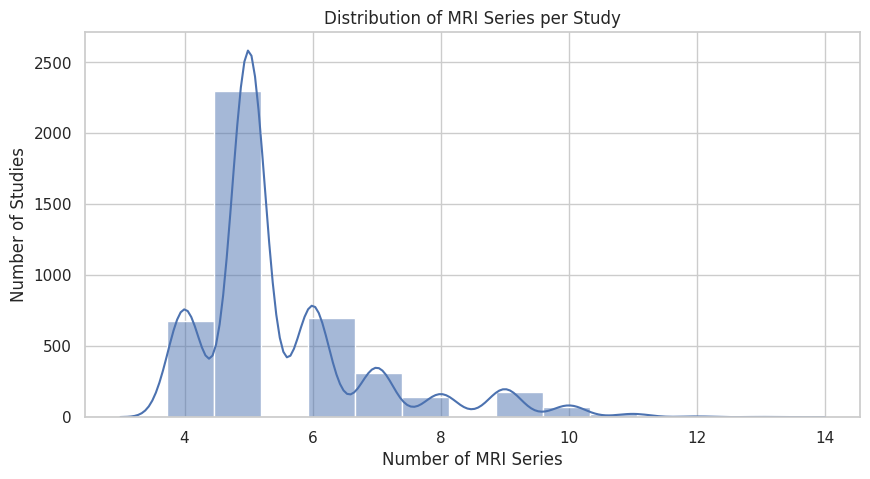

In [89]:
series_per_study = train_series_df.groupby("StudyInstanceUID").size()

plt.figure(figsize=(10, 5))

sns.histplot(series_per_study, bins=15, kde=True)

plt.title("Distribution of MRI Series per Study")
plt.xlabel("Number of MRI Series")
plt.ylabel("Number of Studies")

plt.show()

In [90]:
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

In [91]:
target_columns = [
    "ACL",
    "MCL",
    "Medial Meniscus",
    "Lateral Meniscus",
    "Medial OA",
    "Lateral OA",
    "PF OA",
    "Effusion",
    "Synovitis",
    "Baker's",
    "Contusion",
    "Fracture"
]

print("Total training studies:", len(train))

print("\nLabeled values:")
print(train[target_columns].notna().sum())

print("\nCompletely labeled studies:")
print(train[target_columns].notna().all(axis=1).sum())

Total training studies: 4407

Labeled values:
ACL                 58
MCL                 58
Medial Meniscus     58
Lateral Meniscus    58
Medial OA           58
Lateral OA          58
PF OA               58
Effusion            58
Synovitis           58
Baker's             58
Contusion           58
Fracture            58
dtype: int64

Completely labeled studies:
58


In [92]:
labeled_train = train[
    train[target_columns].notna().all(axis=1)
].copy()

print("Total studies:", len(train))
print("Fully labeled studies:", len(labeled_train))

display(labeled_train.head())

Total studies: 4407
Fully labeled studies: 58


,StudyInstanceUID,Report,ACL,MCL,Medial Meniscus,Lateral Meniscus,Medial OA,Lateral OA,PF OA,Effusion,Synovitis,Baker's,Contusion,Fracture
29,1.2.826.0.1.3680043.8.498.10095687747295410396...,Antecedentes Clínicos:\nEsguince rodilla. [DAT...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0
63,1.2.826.0.1.3680043.8.498.10170898615867673028...,The study reveals normal knee joint alignment...,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
109,1.2.826.0.1.3680043.8.498.10306159113324811538...,Exam Type: MRI KNEE RIGHT WO CONTRAST\nExam Da...,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
445,1.2.826.0.1.3680043.8.498.11287937729196958426...,"MRI of left Knee with \n-3-Plane Loc R'T, Sag ...",0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
470,1.2.826.0.1.3680043.8.498.11382021393803389951...,"In the medial compartment, there is longitudi...",1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [93]:
display(labeled_train[target_columns].head(10))

,ACL,MCL,Medial Meniscus,Lateral Meniscus,Medial OA,Lateral OA,PF OA,Effusion,Synovitis,Baker's,Contusion,Fracture
29,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0
63,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
109,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
445,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
470,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
533,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0
537,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0
607,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
632,0.0,0.0,1.0,1.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0
656,0.0,0.0,0.0,1.0,0.0,1.0,1.0,1.0,1.0,1.0,0.0,0.0


In [94]:
y = labeled_train[target_columns].values.astype("float32")

print("Target shape:", y.shape)
print("First target:", y[0])

Target shape: (58, 12)
First target: [0. 0. 0. 0. 0. 0. 1. 1. 0. 0. 0. 0.]


In [95]:
import tensorflow as tf
from tensorflow import keras

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.20.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


In [96]:
import numpy as np

def prepare_for_keras(image):
    image = np.stack([image, image, image], axis=-1)

    return image.astype(np.float32)

In [97]:
keras_image = prepare_for_keras(resized_image)

print("Shape:", keras_image.shape)
print("Minimum:", keras_image.min())
print("Maximum:", keras_image.max())

Shape: (224, 224, 3)
Minimum: 0.0
Maximum: 0.9607843


In [98]:
from tensorflow.keras.applications import EfficientNetB0

base_model = EfficientNetB0(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3),
    pooling="avg"
)

base_model.trainable = False

print("EfficientNetB0 loaded successfully!")

I0000 00:00:1794570089.148058      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1794570089.152719      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
EfficientNetB0 loaded successfully!


In [99]:
sample = keras_image[np.newaxis, ...]
features = base_model(sample, training=False)

print("Input shape:", sample.shape)
print("Feature shape:", features.shape)

Input shape: (1, 224, 224, 3)
Feature shape: (1, 1280)


In [100]:
from tensorflow.keras import layers
inputs = keras.Input(shape=(224, 224, 3))

x = base_model(inputs, training=False)

x = layers.Dense(256, activation="relu")(x)

x = layers.Dropout(0.3)(x)

outputs = layers.Dense(
    12,
    activation="sigmoid"
)(x)
model = keras.Model(
    inputs=inputs,
    outputs=outputs
)

print("Knee classification model created!")

Knee classification model created!


In [101]:
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 1280)           │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 12)             │         3,084 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,380,591 (16.71 MB)

 Trainable params: 331,020 (1.26 MB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [102]:
# Identify fully labeled and unlabeled studies
fully_labeled = train[target_columns].notna().all(axis=1)

print("Fully labeled studies:", fully_labeled.sum())
print("Studies without labels:", (~fully_labeled).sum())

# Check whether reports are available
print("\nReports available:", train["Report"].notna().sum())

# Check report lengths
print("\nReport length summary:")
print(train["Report"].dropna().astype(str).str.len().describe())

# Display two example reports
print("\nExample reports:\n")

for report in train["Report"].dropna().head(2):
    print(report[:1500])
    print("\n" + "=" * 60 + "\n")

Fully labeled studies: 58
Studies without labels: 4349

Reports available: 4407

Report length summary:
count    4407.000000
mean     1097.905605
std       693.948925
min        52.000000
25%       587.500000
50%       977.000000
75%      1459.500000
max      4743.000000
Name: Report, dtype: float64

Example reports:

Técnica: RMN de la rodilla. Resultados: Rotura de menisco interno. Signo de necrosis avascular subcondral en el cóndilo femoral medial. Artrosis femorotibial medial. Derrame. . Impresión: Rotura de menisco interno. Signo de necrosis avascular subcondral en el cóndilo femoral medial. Artrosis femorotibial medial. Derrame.


[DATE]: * MR Knie Rechts 15ch AA Klinische Inlichtingen: [DATE]. Diagnostische vraagstellling: Meniscusscheur/mediaal? Scanprotocol (DRB) : sag intermediair gewogen seq zonder en met fs, ax/ cor pd gewogen seq fs, cor T1 gewogen seq Bevindingen:




In [103]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[
        keras.metrics.AUC(
            name="auc",
            multi_label=True,
            num_labels=12
        )
    ]
)

print("Model compiled successfully!")

Model compiled successfully!


In [104]:
print("Training data shape:", train.shape)
print("Number of studies:", train["StudyInstanceUID"].nunique())

print("\nLabel columns:")
print(target_columns)

print("\nMissing values in each label:")
print(train[target_columns].isna().sum())

print("\nFirst five rows of labels:")
display(train[["StudyInstanceUID"] + target_columns].head())

Training data shape: (4407, 14)
Number of studies: 4407

Label columns:
['ACL', 'MCL', 'Medial Meniscus', 'Lateral Meniscus', 'Medial OA', 'Lateral OA', 'PF OA', 'Effusion', 'Synovitis', "Baker's", 'Contusion', 'Fracture']

Missing values in each label:
ACL                 4349
MCL                 4349
Medial Meniscus     4349
Lateral Meniscus    4349
Medial OA           4349
Lateral OA          4349
PF OA               4349
Effusion            4349
Synovitis           4349
Baker's             4349
Contusion           4349
Fracture            4349
dtype: int64

First five rows of labels:


,StudyInstanceUID,ACL,MCL,Medial Meniscus,Lateral Meniscus,Medial OA,Lateral OA,PF OA,Effusion,Synovitis,Baker's,Contusion,Fracture
0,1.2.826.0.1.3680043.8.498.10004873229099053869...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1.2.826.0.1.3680043.8.498.10004945927472656027...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1.2.826.0.1.3680043.8.498.10009278692606631573...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,1.2.826.0.1.3680043.8.498.10009639203170750274...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,1.2.826.0.1.3680043.8.498.10013663742400736029...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [105]:
labeled_train = train[
    train[target_columns].notna().all(axis=1)
].copy()

print("Labeled studies:", len(labeled_train))

print("\nLabel distribution:")

for column in target_columns:
    print(f"\n{column}:")
    print(labeled_train[column].value_counts(dropna=False))

print("\nExample labeled studies:")

display(
    labeled_train[
        ["StudyInstanceUID", "Report"] + target_columns
    ].head(3)
)

Labeled studies: 58

Label distribution:

ACL:
ACL
0.0    34
1.0    24
Name: count, dtype: int64

MCL:
MCL
0.0    49
1.0     9
Name: count, dtype: int64

Medial Meniscus:
Medial Meniscus
0.0    32
1.0    26
Name: count, dtype: int64

Lateral Meniscus:
Lateral Meniscus
0.0    35
1.0    23
Name: count, dtype: int64

Medial OA:
Medial OA
0.0    43
1.0    15
Name: count, dtype: int64

Lateral OA:
Lateral OA
0.0    47
1.0    11
Name: count, dtype: int64

PF OA:
PF OA
0.0    37
1.0    21
Name: count, dtype: int64

Effusion:
Effusion
1.0    35
0.0    23
Name: count, dtype: int64

Synovitis:
Synovitis
0.0    31
1.0    27
Name: count, dtype: int64

Baker's:
Baker's
0.0    46
1.0    12
Name: count, dtype: int64

Contusion:
Contusion
0.0    39
1.0    19
Name: count, dtype: int64

Fracture:
Fracture
0.0    40
1.0    18
Name: count, dtype: int64

Example labeled studies:


,StudyInstanceUID,Report,ACL,MCL,Medial Meniscus,Lateral Meniscus,Medial OA,Lateral OA,PF OA,Effusion,Synovitis,Baker's,Contusion,Fracture
29,1.2.826.0.1.3680043.8.498.10095687747295410396...,Antecedentes Clínicos:\nEsguince rodilla. [DAT...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0
63,1.2.826.0.1.3680043.8.498.10170898615867673028...,The study reveals normal knee joint alignment...,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
109,1.2.826.0.1.3680043.8.498.10306159113324811538...,Exam Type: MRI KNEE RIGHT WO CONTRAST\nExam Da...,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0


In [106]:
study_labels = labeled_train[
    ["StudyInstanceUID"] + target_columns
].copy()

# Convert labels to float32 for TensorFlow
study_labels[target_columns] = study_labels[target_columns].astype(
    np.float32
)

print("Number of labeled studies:", len(study_labels))
print("Number of target labels:", len(target_columns))
print("Missing labels:", study_labels[target_columns].isna().sum().sum())

display(study_labels.head())

Number of labeled studies: 58
Number of target labels: 12
Missing labels: 0


,StudyInstanceUID,ACL,MCL,Medial Meniscus,Lateral Meniscus,Medial OA,Lateral OA,PF OA,Effusion,Synovitis,Baker's,Contusion,Fracture
29,1.2.826.0.1.3680043.8.498.10095687747295410396...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0
63,1.2.826.0.1.3680043.8.498.10170898615867673028...,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
109,1.2.826.0.1.3680043.8.498.10306159113324811538...,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
445,1.2.826.0.1.3680043.8.498.11287937729196958426...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
470,1.2.826.0.1.3680043.8.498.11382021393803389951...,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [107]:
labeled_series = train_series[
    train_series["StudyInstanceUID"].isin(
        study_labels["StudyInstanceUID"]
    )
].copy()

print("Labeled studies:", study_labels["StudyInstanceUID"].nunique())
print("Matching MRI series:", len(labeled_series))

print("\nMRI series per study:")
print(
    labeled_series.groupby("StudyInstanceUID")
    .size()
    .describe()
)

display(labeled_series.head())

Labeled studies: 58
Matching MRI series: 336

MRI series per study:
count    58.000000
mean      5.793103
std       1.460096
min       4.000000
25%       5.000000
50%       5.000000
75%       6.000000
max       9.000000
dtype: float64


,StudyInstanceUID,SeriesInstanceUID,Fluid_Sensitive,Fat_Suppression,Anatomical_Plane
163,1.2.826.0.1.3680043.8.498.10095687747295410396...,1.2.826.0.1.3680043.8.498.10791858932231443712...,0,0,Sagittal
164,1.2.826.0.1.3680043.8.498.10095687747295410396...,1.2.826.0.1.3680043.8.498.12451507871565834868...,0,0,Coronal
165,1.2.826.0.1.3680043.8.498.10095687747295410396...,1.2.826.0.1.3680043.8.498.21497837050858589852...,1,1,Coronal
166,1.2.826.0.1.3680043.8.498.10095687747295410396...,1.2.826.0.1.3680043.8.498.37372672584387115708...,1,1,Sagittal
167,1.2.826.0.1.3680043.8.498.10095687747295410396...,1.2.826.0.1.3680043.8.498.67495435033389756963...,1,1,Axial


In [108]:
import os

dataset_path = "/kaggle/input/competitions/rsna-knee-abnormality-detection"

# Select the first labeled study
sample_study_id = study_labels.iloc[0]["StudyInstanceUID"]

# Find its MRI series
sample_series = labeled_series[
    labeled_series["StudyInstanceUID"] == sample_study_id
]

print("Study ID:", sample_study_id)
print("Number of series:", len(sample_series))

# Display the series information
display(sample_series)

Study ID: 1.2.826.0.1.3680043.8.498.10095687747295410396510538520594649149
Number of series: 5


,StudyInstanceUID,SeriesInstanceUID,Fluid_Sensitive,Fat_Suppression,Anatomical_Plane
163,1.2.826.0.1.3680043.8.498.10095687747295410396...,1.2.826.0.1.3680043.8.498.10791858932231443712...,0,0,Sagittal
164,1.2.826.0.1.3680043.8.498.10095687747295410396...,1.2.826.0.1.3680043.8.498.12451507871565834868...,0,0,Coronal
165,1.2.826.0.1.3680043.8.498.10095687747295410396...,1.2.826.0.1.3680043.8.498.21497837050858589852...,1,1,Coronal
166,1.2.826.0.1.3680043.8.498.10095687747295410396...,1.2.826.0.1.3680043.8.498.37372672584387115708...,1,1,Sagittal
167,1.2.826.0.1.3680043.8.498.10095687747295410396...,1.2.826.0.1.3680043.8.498.67495435033389756963...,1,1,Axial


In [109]:
import os
study_path = os.path.join(
    dataset_path,
    "train_series",
    sample_study_id
)

print("Study folder exists:", os.path.exists(study_path))

if os.path.exists(study_path):
    print("Series folders:", os.listdir(study_path)[:10])
else:
    print("Study folder not found. Check the study ID and dataset path.")

Study folder exists: True
Series folders: ['1.2.826.0.1.3680043.8.498.12451507871565834868863189854063726441', '1.2.826.0.1.3680043.8.498.10791858932231443712736629517371931282', '1.2.826.0.1.3680043.8.498.21497837050858589852101556928971904198', '1.2.826.0.1.3680043.8.498.67495435033389756963800730529101229430', '1.2.826.0.1.3680043.8.498.37372672584387115708078590109474719429']


In [110]:
series_folders = os.listdir(study_path)

if series_folders:
    first_series_id = series_folders[0]

    series_path = os.path.join(
        study_path,
        first_series_id
    )

    dicom_files = [
        f for f in os.listdir(series_path)
        if f.lower().endswith(".dcm")
    ]

    print("First series ID:", first_series_id)
    print("Number of DICOM slices:", len(dicom_files))
    print("Example files:", dicom_files[:5])
else:
    print("No series folders found.")

First series ID: 1.2.826.0.1.3680043.8.498.12451507871565834868863189854063726441
Number of DICOM slices: 30
Example files: ['1.2.826.0.1.3680043.8.498.12874407468115458497760896711466986200.dcm', '1.2.826.0.1.3680043.8.498.42353135431644446885375280436351259126.dcm', '1.2.826.0.1.3680043.8.498.27686010194017241066130831338578830312.dcm', '1.2.826.0.1.3680043.8.498.54573617248881776540302058338144758105.dcm', '1.2.826.0.1.3680043.8.498.10384632728751245860946475494516521393.dcm']


Original image shape: (384, 384)
Original data type: uint16
Processed image shape: (224, 224, 3)
Minimum intensity: 0.0
Maximum intensity: 0.87388015


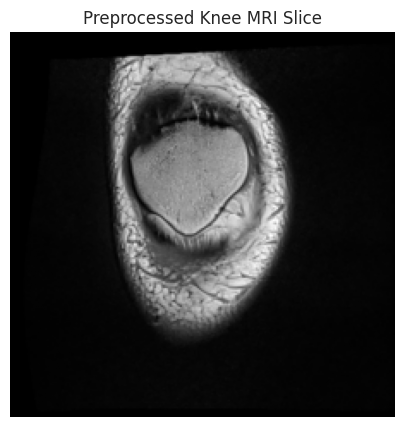

In [111]:
import pydicom
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# Build the path to one DICOM file
dicom_path = os.path.join(
    series_path,
    dicom_files[0]
)

# Read the MRI slice
ds = pydicom.dcmread(dicom_path)
image = ds.pixel_array.astype(np.float32)

print("Original image shape:", image.shape)
print("Original data type:", ds.pixel_array.dtype)

# Apply DICOM intensity rescaling when available
slope = float(getattr(ds, "RescaleSlope", 1))
intercept = float(getattr(ds, "RescaleIntercept", 0))

image = image * slope + intercept

# Normalize intensities to the range 0–1
image_min = image.min()
image_max = image.max()

if image_max > image_min:
    image = (image - image_min) / (image_max - image_min)
else:
    image = np.zeros_like(image)

# Resize to 224 × 224
image = Image.fromarray(image).resize(
    (224, 224),
    Image.Resampling.BILINEAR
)

image = np.asarray(image, dtype=np.float32)

# Convert grayscale to three channels
keras_image = np.stack([image, image, image], axis=-1)

print("Processed image shape:", keras_image.shape)
print("Minimum intensity:", keras_image.min())
print("Maximum intensity:", keras_image.max())

# Display the image
plt.figure(figsize=(5, 5))
plt.imshow(keras_image[:, :, 0], cmap="gray")
plt.title("Preprocessed Knee MRI Slice")
plt.axis("off")
plt.show()

In [112]:

keras_image_255 = keras_image * 255.0
sample = np.expand_dims(keras_image_255, axis=0)

print("Input shape:", sample.shape)
print("Data type:", sample.dtype)
print("Minimum pixel value:", sample.min())
print("Maximum pixel value:", sample.max())

Input shape: (1, 224, 224, 3)
Data type: float32
Minimum pixel value: 0.0
Maximum pixel value: 222.83943


In [113]:
features = base_model(sample, training=False)

print("Feature shape:", features.shape)

Feature shape: (1, 1280)


In [114]:
print("process_study available:", "process_study" in globals())
print("process_series available:", "process_series" in globals())
print("base_model available:", "base_model" in globals())
print("study_labels available:", "study_labels" in globals())

process_study available: True
process_series available: True
base_model available: True
study_labels available: True


In [115]:
# Select one study that has all 12 labels
sample_study_id = study_labels.iloc[0]["StudyInstanceUID"]

print("Study ID:", sample_study_id)

# Process the study
study_images = process_study(sample_study_id)

# Inspect the output
print("Output type:", type(study_images))

if study_images is not None:
    print("Output shape:", np.shape(study_images))
    print("Data type:", np.asarray(study_images).dtype)
    print("Minimum pixel value:", np.min(study_images))
    print("Maximum pixel value:", np.max(study_images))

Study ID: 1.2.826.0.1.3680043.8.498.10095687747295410396510538520594649149
Output type: <class 'numpy.ndarray'>
Output shape: (5, 8, 224, 224)
Data type: float32
Minimum pixel value: 0.0
Maximum pixel value: 0.9764706


In [116]:
first_series = study_images[0]
first_slice = first_series[0]

first_slice_rgb = np.stack(
    [first_slice, first_slice, first_slice],
    axis=-1
)

first_slice_rgb = first_slice_rgb * 255.0
sample_batch = np.expand_dims(first_slice_rgb, axis=0)

print("Original study shape:", study_images.shape)
print("Single slice shape:", first_slice.shape)
print("RGB slice shape:", first_slice_rgb.shape)
print("Batch shape:", sample_batch.shape)
print("Pixel range:", sample_batch.min(), "to", sample_batch.max())

Original study shape: (5, 8, 224, 224)
Single slice shape: (224, 224)
RGB slice shape: (224, 224, 3)
Batch shape: (1, 224, 224, 3)
Pixel range: 0.0 to 214.0


In [117]:
features = base_model(sample_batch, training=False)

print("Input shape:", sample_batch.shape)
print("Feature shape:", features.shape)

Input shape: (1, 224, 224, 3)
Feature shape: (1, 1280)


In [118]:
sample_labels = study_labels.iloc[0][target_columns]

print("Study ID:", study_labels.iloc[0]["StudyInstanceUID"])
print("\nLabels:")
print(sample_labels)

print("\nLabel shape:", sample_labels.shape)
print("\nMissing labels:", sample_labels.isna().sum())

Study ID: 1.2.826.0.1.3680043.8.498.10095687747295410396510538520594649149

Labels:
ACL                 0.0
MCL                 0.0
Medial Meniscus     0.0
Lateral Meniscus    0.0
Medial OA           0.0
Lateral OA          0.0
PF OA               1.0
Effusion            1.0
Synovitis           0.0
Baker's             0.0
Contusion           0.0
Fracture            0.0
Name: 29, dtype: object

Label shape: (12,)

Missing labels: 0


In [119]:
# Extract the 12 labels for every fully labeled study
y = study_labels[target_columns].to_numpy(dtype=np.float32)

print("Label matrix shape:", y.shape)
print("Number of studies:", y.shape[0])
print("Number of abnormalities:", y.shape[1])
print("Data type:", y.dtype)

# Display the labels for the first study
print("\nFirst study's labels:")
print(y[0])

Label matrix shape: (58, 12)
Number of studies: 58
Number of abnormalities: 12
Data type: float32

First study's labels:
[0. 0. 0. 0. 0. 0. 1. 1. 0. 0. 0. 0.]


In [120]:
# Count positive and negative labels for each abnormality
positive_counts = study_labels[target_columns].sum()
negative_counts = len(study_labels) - positive_counts

label_summary = pd.DataFrame({
    "Abnormality": target_columns,
    "Positive cases": positive_counts.values.astype(int),
    "Negative cases": negative_counts.values.astype(int)
})

print(label_summary.to_string(index=False))

     Abnormality  Positive cases  Negative cases
             ACL              24              34
             MCL               9              49
 Medial Meniscus              26              32
Lateral Meniscus              23              35
       Medial OA              15              43
      Lateral OA              11              47
           PF OA              21              37
        Effusion              35              23
       Synovitis              27              31
         Baker's              12              46
       Contusion              19              39
        Fracture              18              40


In [121]:
from sklearn.model_selection import train_test_split
study_ids = study_labels["StudyInstanceUID"].to_numpy()

y = study_labels[target_columns].to_numpy(dtype=np.float32)
train_ids, val_ids, y_train, y_val = train_test_split(
    study_ids,
    y,
    test_size=0.2,
    random_state=42
)

print("Training studies:", len(train_ids))
print("Validation studies:", len(val_ids))
print("Training labels shape:", y_train.shape)
print("Validation labels shape:", y_val.shape)

Training studies: 46
Validation studies: 12
Training labels shape: (46, 12)
Validation labels shape: (12, 12)


In [122]:
# Count positive cases in each split
train_positive = y_train.sum(axis=0).astype(int)
val_positive = y_val.sum(axis=0).astype(int)

split_summary = pd.DataFrame({
    "Abnormality": target_columns,
    "Training positives": train_positive,
    "Validation positives": val_positive,
    "Validation negatives": len(y_val) - val_positive
})

print(split_summary.to_string(index=False))

     Abnormality  Training positives  Validation positives  Validation negatives
             ACL                  21                     3                     9
             MCL                   6                     3                     9
 Medial Meniscus                  21                     5                     7
Lateral Meniscus                  19                     4                     8
       Medial OA                  11                     4                     8
      Lateral OA                  11                     0                    12
           PF OA                  17                     4                     8
        Effusion                  27                     8                     4
       Synovitis                  23                     4                     8
         Baker's                  10                     2                    10
       Contusion                  17                     2                    10
        Fracture            

In [123]:
%pip install iterative-stratification

Note: you may need to restart the kernel to use updated packages.


In [124]:
from iterstrat.ml_stratifiers import MultilabelStratifiedShuffleSplit

print("Iterative multilabel stratification is ready!")

Iterative multilabel stratification is ready!


In [125]:
from iterstrat.ml_stratifiers import MultilabelStratifiedShuffleSplit

# Prepare study IDs and their 12 labels
study_ids = study_labels["StudyInstanceUID"].to_numpy()
y = study_labels[target_columns].to_numpy(dtype=np.float32)

# Create a multilabel-stratified split
splitter = MultilabelStratifiedShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, val_idx = next(splitter.split(study_ids, y))

train_ids = study_ids[train_idx]
val_ids = study_ids[val_idx]

y_train = y[train_idx]
y_val = y[val_idx]

print("Training studies:", len(train_ids))
print("Validation studies:", len(val_ids))

# Compare positive examples across both sets
train_positive = y_train.sum(axis=0).astype(int)
val_positive = y_val.sum(axis=0).astype(int)

split_summary = pd.DataFrame({
    "Abnormality": target_columns,
    "Training positives": train_positive,
    "Validation positives": val_positive,
    "Validation negatives": len(y_val) - val_positive
})

print("\nLabel distribution:")
print(split_summary.to_string(index=False))

Training studies: 47
Validation studies: 11

Label distribution:
     Abnormality  Training positives  Validation positives  Validation negatives
             ACL                  19                     5                     6
             MCL                   7                     2                     9
 Medial Meniscus                  22                     4                     7
Lateral Meniscus                  18                     5                     6
       Medial OA                  12                     3                     8
      Lateral OA                   9                     2                     9
           PF OA                  17                     4                     7
        Effusion                  28                     7                     4
       Synovitis                  21                     6                     5
         Baker's                  10                     2                     9
       Contusion                  14        

In [126]:
print("EfficientNet input shape:", base_model.input_shape)
print("EfficientNet output shape:", base_model.output_shape)
print("EfficientNet trainable:", base_model.trainable)

print("\nTraining studies:", len(train_ids))
print("Validation studies:", len(val_ids))
print("Number of target labels:", len(target_columns))

EfficientNet input shape: (None, 224, 224, 3)
EfficientNet output shape: (None, 1280)
EfficientNet trainable: False

Training studies: 47
Validation studies: 11
Number of target labels: 12


In [127]:
def extract_study_features(study_id, split="train", max_slices=8):
    """
    Extract one 1280-dimensional feature vector per MRI study.

    split="train" processes a training study.
    split="test" processes a test study.
    """

    # Process the study from the correct dataset
    study_images = process_study(
        study_id,
        split=split,
        num_slices=max_slices
    )

    if study_images is None or study_images.size == 0:
        raise ValueError(f"No MRI images found for study: {study_id}")

    if study_images.ndim != 4:
        raise ValueError(
            f"Unexpected image shape for {study_id}: {study_images.shape}"
        )

    # Select slices from each series
    selected_slices = []

    for series in study_images:
        indices = np.linspace(
            0,
            len(series) - 1,
            num=min(max_slices, len(series)),
            dtype=int
        )

        selected_slices.extend(series[indices])

    # Convert grayscale images to three channels
    images = np.asarray(selected_slices, dtype=np.float32)
    images = images[..., np.newaxis]
    images = np.repeat(images, 3, axis=-1)

    # Scale pixel values for EfficientNetB0
    images = images * 255.0

    # Extract features in small batches
    feature_batches = []

    for start in range(0, len(images), 4):
        batch = tf.convert_to_tensor(images[start:start + 4])
        batch_features = base_model(batch, training=False)
        feature_batches.append(batch_features.numpy())

    features = np.concatenate(feature_batches, axis=0)

    # Average features across the study's slices
    study_feature_vector = features.mean(axis=0)

    return study_feature_vector

In [128]:
test_study_id = train_ids[0]

test_features = extract_study_features(test_study_id)

print("Study ID:", test_study_id)
print("Extracted feature shape:", test_features.shape)
print("Data type:", test_features.dtype)
print("All values finite:", np.isfinite(test_features).all())

Study ID: 1.2.826.0.1.3680043.8.498.10095687747295410396510538520594649149
Extracted feature shape: (1280,)
Data type: float32
All values finite: True


In [129]:
import time
def extract_features_for_split(study_ids, split_name):
    all_features = []

    total = len(study_ids)
    start_time = time.time()

    for i, study_id in enumerate(study_ids, start=1):
        features = extract_study_features(study_id)
        all_features.append(features)

        print(
            f"\r{split_name}: processed {i}/{total} studies",
            end=""
        )

    print()

    elapsed = time.time() - start_time
    print(f"{split_name} extraction time: {elapsed / 60:.2f} minutes")

    return np.stack(all_features).astype(np.float32)


# Extract training features
X_train = extract_features_for_split(train_ids, "Training")

# Extract validation features
X_val = extract_features_for_split(val_ids, "Validation")

print("\nTraining features shape:", X_train.shape)
print("Validation features shape:", X_val.shape)
print("Training labels shape:", y_train.shape)
print("Validation labels shape:", y_val.shape)

Training: processed 47/47 studies
Training extraction time: 5.37 minutes
Validation: processed 11/11 studies
Validation extraction time: 1.09 minutes

Training features shape: (47, 1280)
Validation features shape: (11, 1280)
Training labels shape: (47, 12)
Validation labels shape: (11, 12)


In [130]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.multiclass import OneVsRestClassifier
from sklearn.linear_model import LogisticRegression

classifier = make_pipeline(
    StandardScaler(),
    OneVsRestClassifier(
        LogisticRegression(
            C=0.1,
            max_iter=1000,
            class_weight="balanced",
            random_state=42
        )
    )
)

classifier.fit(X_train, y_train)

print("Classifier training completed!")
print("Training studies:", X_train.shape[0])
print("Features per study:", X_train.shape[1])
print("Abnormalities predicted:", y_train.shape[1])

Classifier training completed!
Training studies: 47
Features per study: 1280
Abnormalities predicted: 12


In [131]:
# Predict probabilities for the 12 abnormalities
y_prob = classifier.predict_proba(X_val)

print("Prediction matrix shape:", y_prob.shape)
print("\nProbabilities for the first validation study:")

for name, probability in zip(target_columns, y_prob[0]):
    print(f"{name}: {probability:.4f}")

Prediction matrix shape: (11, 12)

Probabilities for the first validation study:
ACL: 0.8064
MCL: 0.0516
Medial Meniscus: 0.4558
Lateral Meniscus: 0.0608
Medial OA: 0.0690
Lateral OA: 0.0035
PF OA: 0.1472
Effusion: 0.4996
Synovitis: 0.1234
Baker's: 0.0441
Contusion: 0.8098
Fracture: 0.0318


In [132]:
actual_labels = y_val[0]
predicted_probabilities = y_prob[0]
predicted_labels = (predicted_probabilities >= 0.5).astype(int)

print("FIRST VALIDATION STUDY")
print("-" * 65)
print(f"{'Abnormality':<22} {'Actual':<10} {'Probability':<14} {'Predicted'}")
print("-" * 65)

for name, actual, probability, predicted in zip(
    target_columns,
    actual_labels,
    predicted_probabilities,
    predicted_labels
):
    print(
        f"{name:<22} {int(actual):<10} "
        f"{probability:<14.4f} {predicted}"
    )

FIRST VALIDATION STUDY
-----------------------------------------------------------------
Abnormality            Actual     Probability    Predicted
-----------------------------------------------------------------
ACL                    0          0.8064         1
MCL                    0          0.0516         0
Medial Meniscus        0          0.4558         0
Lateral Meniscus       1          0.0608         0
Medial OA              0          0.0690         0
Lateral OA             0          0.0035         0
PF OA                  1          0.1472         0
Effusion               0          0.4996         0
Synovitis              1          0.1234         0
Baker's                0          0.0441         0
Contusion              0          0.8098         1
Fracture               0          0.0318         0


In [133]:
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    roc_auc_score,
    f1_score
)

y_pred = (y_prob >= 0.5).astype(int)

# Calculate metrics separately for each abnormality
precision, recall, f1, support = precision_recall_fscore_support(
    y_val,
    y_pred,
    average=None,
    zero_division=0
)

auc_scores = []

for i, name in enumerate(target_columns):
    if len(np.unique(y_val[:, i])) == 2:
        auc = roc_auc_score(y_val[:, i], y_prob[:, i])
    else:
        auc = np.nan

    auc_scores.append(auc)

results = pd.DataFrame({
    "Abnormality": target_columns,
    "Precision": precision,
    "Recall": recall,
    "F1-Score": f1,
    "ROC-AUC": auc_scores,
    "Actual Positives": y_val.sum(axis=0).astype(int),
    "Predicted Positives": y_pred.sum(axis=0).astype(int)
})

print("PER-ABNORMALITY EVALUATION")
display(results.round(3))

print("\nOVERALL MODEL EVALUATION")
print("-" * 40)

print(f"Label-wise accuracy: {accuracy_score(y_val, y_pred):.3f}")
print(f"Micro F1-score:      {f1_score(y_val, y_pred, average='micro', zero_division=0):.3f}")
print(f"Macro F1-score:      {f1_score(y_val, y_pred, average='macro', zero_division=0):.3f}")
print(f"Mean ROC-AUC:        {np.nanmean(auc_scores):.3f}")

PER-ABNORMALITY EVALUATION


,Abnormality,Precision,Recall,F1-Score,ROC-AUC,Actual Positives,Predicted Positives
0,ACL,0.667,0.400,0.500,0.633,5,3
1,MCL,0.000,0.000,0.000,0.500,2,2
2,Medial Meniscus,0.500,0.750,0.600,0.679,4,6
3,Lateral Meniscus,0.400,0.400,0.400,0.500,5,5
4,Medial OA,0.400,0.667,0.500,0.875,3,5
5,Lateral OA,1.000,0.500,0.667,0.778,2,1
6,PF OA,0.333,0.250,0.286,0.429,4,3
7,Effusion,0.875,1.000,0.933,1.000,7,8
8,Synovitis,0.667,0.667,0.667,0.633,6,6
9,Baker's,0.400,1.000,0.571,0.667,2,5



OVERALL MODEL EVALUATION
----------------------------------------
Label-wise accuracy: 0.000
Micro F1-score:      0.542
Macro F1-score:      0.484
Mean ROC-AUC:        0.685


In [134]:
accuracy_score(y_val, y_pred)

0.0

In [135]:
label_accuracy = np.mean(y_val == y_pred)

print(f"Individual-label accuracy: {label_accuracy:.3f}")
print(f"Individual-label accuracy: {label_accuracy * 100:.2f}%")

exact_match_accuracy = np.mean(
    np.all(y_val == y_pred, axis=1)
)

print(f"\nExact-match accuracy: {exact_match_accuracy:.3f}")
print(
    f"Studies with all 12 labels correct: "
    f"{int(np.sum(np.all(y_val == y_pred, axis=1)))} out of {len(y_val)}"
)

Individual-label accuracy: 0.667
Individual-label accuracy: 66.67%

Exact-match accuracy: 0.000
Studies with all 12 labels correct: 0 out of 11


In [136]:
import os

os.makedirs("/kaggle/working/saved_features", exist_ok=True)

np.savez_compressed(
    "/kaggle/working/saved_features/knee_features.npz",
    X_train=X_train,
    X_val=X_val,
    y_train=y_train,
    y_val=y_val,
    target_columns=np.array(target_columns),
    train_ids=train_ids,
    val_ids=val_ids
)

print("Features saved successfully!")

print("Training features:", X_train.shape)
print("Validation features:", X_val.shape)
print("Training labels:", y_train.shape)
print("Validation labels:", y_val.shape)

print("\nSaved file:")
print("/kaggle/working/saved_features/knee_features.npz")

Features saved successfully!
Training features: (47, 1280)
Validation features: (11, 1280)
Training labels: (47, 12)
Validation labels: (11, 12)

Saved file:
/kaggle/working/saved_features/knee_features.npz


In [137]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.multiclass import OneVsRestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import f1_score, roc_auc_score

rf_classifier = make_pipeline(
    SimpleImputer(strategy="median"),
    OneVsRestClassifier(
        RandomForestClassifier(
            n_estimators=200,
            max_depth=5,
            min_samples_leaf=2,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        )
    )
)

rf_classifier.fit(X_train, y_train)

print("Random Forest training completed!")
print("Training studies:", X_train.shape[0])
print("Features per study:", X_train.shape[1])
print("Abnormalities predicted:", y_train.shape[1])

rf_prob = rf_classifier.predict_proba(X_val)

rf_pred = (rf_prob >= 0.5).astype(int)
rf_label_accuracy = np.mean(y_val == rf_pred)

rf_micro_f1 = f1_score(
    y_val, rf_pred,
    average="micro",
    zero_division=0
)

rf_macro_f1 = f1_score(
    y_val, rf_pred,
    average="macro",
    zero_division=0
)

rf_auc_scores = []

for i in range(len(target_columns)):
    if len(np.unique(y_val[:, i])) == 2:
        rf_auc_scores.append(
            roc_auc_score(y_val[:, i], rf_prob[:, i])
        )

rf_mean_auc = np.mean(rf_auc_scores)

print("RANDOM FOREST RESULTS")
print("-" * 35)
print(f"Individual-label accuracy: {rf_label_accuracy:.3f}")
print(f"Micro F1-score:            {rf_micro_f1:.3f}")
print(f"Macro F1-score:            {rf_macro_f1:.3f}")
print(f"Mean ROC-AUC:              {rf_mean_auc:.3f}")

Random Forest training completed!
Training studies: 47
Features per study: 1280
Abnormalities predicted: 12
RANDOM FOREST RESULTS
-----------------------------------
Individual-label accuracy: 0.705
Micro F1-score:            0.506
Macro F1-score:            0.375
Mean ROC-AUC:              0.641


In [138]:
rf_prob = rf_classifier.predict_proba(X_val)

rf_pred = (rf_prob >= 0.5).astype(int)

rf_label_accuracy = np.mean(y_val == rf_pred)

rf_micro_f1 = f1_score(
    y_val, rf_pred,
    average="micro",
    zero_division=0
)

rf_macro_f1 = f1_score(
    y_val, rf_pred,
    average="macro",
    zero_division=0
)

rf_auc_scores = []

for i in range(len(target_columns)):
    if len(np.unique(y_val[:, i])) == 2:
        rf_auc_scores.append(
            roc_auc_score(y_val[:, i], rf_prob[:, i])
        )

rf_mean_auc = np.mean(rf_auc_scores)

print("RANDOM FOREST RESULTS")
print("-" * 35)
print(f"Individual-label accuracy: {rf_label_accuracy:.3f}")
print(f"Micro F1-score:            {rf_micro_f1:.3f}")
print(f"Macro F1-score:            {rf_macro_f1:.3f}")
print(f"Mean ROC-AUC:              {rf_mean_auc:.3f}")

RANDOM FOREST RESULTS
-----------------------------------
Individual-label accuracy: 0.705
Micro F1-score:            0.506
Macro F1-score:            0.375
Mean ROC-AUC:              0.641


In [139]:
import joblib
import os

os.makedirs("/kaggle/working/saved_models", exist_ok=True)

model_path = "/kaggle/working/saved_models/knee_logistic_regression.joblib"

joblib.dump(classifier, model_path)

print("Model saved successfully!")
print("Location:", model_path)

Model saved successfully!
Location: /kaggle/working/saved_models/knee_logistic_regression.joblib


In [140]:
import joblib

loaded_model = joblib.load(
    "/kaggle/working/saved_models/knee_logistic_regression.joblib"
)

loaded_probabilities = loaded_model.predict_proba(X_val)

print("Model loaded successfully!")
print("Prediction shape:", loaded_probabilities.shape)
print("Expected shape:", (11, 12))

Model loaded successfully!
Prediction shape: (11, 12)
Expected shape: (11, 12)


In [141]:
import joblib
import json
output_dir = "/kaggle/working/knee_model_artifacts"
os.makedirs(output_dir, exist_ok=True)

np.savez_compressed(
    os.path.join(output_dir, "knee_features.npz"),
    X_train=X_train,
    X_val=X_val,
    y_train=y_train,
    y_val=y_val,
    train_ids=train_ids,
    val_ids=val_ids,
    target_columns=np.array(target_columns)
)

joblib.dump(
    classifier,
    os.path.join(output_dir, "logistic_regression.joblib")
)

experiment_info = {
    "feature_extractor": "EfficientNetB0",
    "pretrained_weights": "ImageNet",
    "feature_dimension": 1280,
    "classifier": "OneVsRest Logistic Regression",
    "training_studies": int(len(train_ids)),
    "validation_studies": int(len(val_ids)),
    "number_of_abnormalities": len(target_columns),
    "random_state": 42,
    "decision_threshold": 0.5
}

with open(
    os.path.join(output_dir, "experiment_info.json"),
    "w"
) as file:
    json.dump(experiment_info, file, indent=4)

print("Experiment artifacts saved successfully!")
print("\nFiles created:")

for filename in os.listdir(output_dir):
    print("-", filename)

Experiment artifacts saved successfully!

Files created:
- knee_features.npz
- logistic_regression.joblib
- experiment_info.json


In [142]:
import inspect
import os

output_dir = "/kaggle/working/knee_model_artifacts"
os.makedirs(output_dir, exist_ok=True)

# Collect the existing function definitions
functions_to_save = [
    process_series,
    process_study,
    extract_study_features
]

with open(
    os.path.join(output_dir, "feature_extraction.py"),
    "w"
) as file:

    file.write('"""MRI preprocessing and feature extraction functions."""\n\n')

    for function in functions_to_save:
        file.write(inspect.getsource(function))
        file.write("\n\n")

print("Feature-extraction functions saved!")
print("Location:", os.path.join(output_dir, "feature_extraction.py"))

Feature-extraction functions saved!
Location: /kaggle/working/knee_model_artifacts/feature_extraction.py


In [143]:
# Display the saved feature-extraction code

file_path = (
    "/kaggle/working/knee_model_artifacts/"
    "feature_extraction.py"
)

with open(file_path, "r") as file:
    saved_code = file.read()

print(saved_code)

"""MRI preprocessing and feature extraction functions."""

def process_series(series_path, num_slices=8, image_size=(224, 224)):
    # Get DICOM files
    files = [
        os.path.join(series_path, f)
        for f in os.listdir(series_path)
        if f.endswith(".dcm")
    ]

    # Read DICOM files
    slices = [pydicom.dcmread(f) for f in files]

    # Get slice direction
    orientation = np.array(
        slices[0].ImageOrientationPatient,
        dtype=float
    )

    row_direction = orientation[:3]
    column_direction = orientation[3:]

    slice_direction = np.cross(
        row_direction,
        column_direction
    )

    # Sort using physical position
    positions = []

    for ds in slices:
        position = np.array(
            ds.ImagePositionPatient,
            dtype=float
        )

        distance = np.dot(
            position,
            slice_direction
        )

        positions.append(distance)

    slices = [
        ds for _, ds in sorted(
           

In [144]:
import joblib
from tensorflow.keras.applications import EfficientNetB0

# Path to our saved classifier
model_path = (
    "/kaggle/working/knee_model_artifacts/"
    "logistic_regression.joblib"
)

# Load the trained classifier
classifier = joblib.load(model_path)

# Initialize the same pretrained feature extractor
base_model = EfficientNetB0(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3),
    pooling="avg"
)

# Freeze the feature extractor
base_model.trainable = False

print("Classifier loaded successfully!")
print("EfficientNetB0 loaded successfully!")
print("Feature extractor trainable:", base_model.trainable)
print("Expected features per study:", base_model.output_shape[-1])

Classifier loaded successfully!
EfficientNetB0 loaded successfully!
Feature extractor trainable: False
Expected features per study: 1280


In [145]:
import numpy as np

study_id = val_ids[0]

print("Selected study:", study_id)

study_features = extract_study_features(study_id)

print("\nFeature extraction completed!")
print("Feature vector shape:", study_features.shape)

study_features = study_features.reshape(1, -1)

probabilities = classifier.predict_proba(study_features)[0]

print("\nPREDICTED ABNORMALITY PROBABILITIES")
print("-" * 55)

for name, probability in zip(target_columns, probabilities):
    print(f"{name:<22} {probability:.4f}")

Selected study: 1.2.826.0.1.3680043.8.498.10170898615867673028696505248839028269

Feature extraction completed!
Feature vector shape: (1280,)

PREDICTED ABNORMALITY PROBABILITIES
-------------------------------------------------------
ACL                    0.8064
MCL                    0.0516
Medial Meniscus        0.4558
Lateral Meniscus       0.0608
Medial OA              0.0690
Lateral OA             0.0035
PF OA                  0.1472
Effusion               0.4996
Synovitis              0.1234
Baker's                0.0441
Contusion              0.8098
Fracture               0.0318


In [146]:
def predict_study(study_id):
    """
    Predict probabilities for the 12 knee abnormalities
    in a study using the existing feature extractor
    and trained classifier.
    """

    features = extract_study_features(study_id)

    features = features.reshape(1, -1)

    probabilities = classifier.predict_proba(features)[0]

    results = []

    for name, probability in zip(target_columns, probabilities):
        results.append({
            "Abnormality": name,
            "Probability": round(float(probability), 4),
            "Predicted positive": bool(probability >= 0.5)
        })

    return results


print("Prediction function created successfully!")

Prediction function created successfully!


In [147]:
study_id = val_ids[0]

predictions = predict_study(study_id)

for prediction in predictions:
    print(
        f"{prediction['Abnormality']:<22} "
        f"Probability: {prediction['Probability']:.4f} | "
        f"Positive: {prediction['Predicted positive']}"
    )

ACL                    Probability: 0.8064 | Positive: True
MCL                    Probability: 0.0516 | Positive: False
Medial Meniscus        Probability: 0.4558 | Positive: False
Lateral Meniscus       Probability: 0.0608 | Positive: False
Medial OA              Probability: 0.0690 | Positive: False
Lateral OA             Probability: 0.0035 | Positive: False
PF OA                  Probability: 0.1472 | Positive: False
Effusion               Probability: 0.4996 | Positive: False
Synovitis              Probability: 0.1234 | Positive: False
Baker's                Probability: 0.0441 | Positive: False
Contusion              Probability: 0.8098 | Positive: True
Fracture               Probability: 0.0318 | Positive: False


In [148]:
import os

test_path = os.path.join(dataset_path, "test_series")

print("Test directory exists:", os.path.exists(test_path))

if os.path.exists(test_path):
    test_studies = os.listdir(test_path)

    print("Number of test studies:", len(test_studies))
    print("First 5 test study IDs:")

    for study_id in test_studies[:5]:
        print(study_id)

Test directory exists: True
Number of test studies: 3
First 5 test study IDs:
1.2.826.0.1.3680043.8.498.10062861783145312629332250977456991776
1.2.826.0.1.3680043.8.498.10067514707072572280263481548497591402
1.2.826.0.1.3680043.8.498.10047035057544427318018579121635276191


In [149]:
import os

for study_id in test_studies:
    study_path = os.path.join(test_path, study_id)

    series = [
        item for item in os.listdir(study_path)
        if os.path.isdir(os.path.join(study_path, item))
    ]

    print(f"\nStudy ID: {study_id}")
    print(f"Number of series: {len(series)}")

    if series:
        first_series_path = os.path.join(study_path, series[0])

        dicom_files = [
            item for item in os.listdir(first_series_path)
            if item.lower().endswith(".dcm")
        ]

        print(f"DICOM images in first series: {len(dicom_files)}")


Study ID: 1.2.826.0.1.3680043.8.498.10062861783145312629332250977456991776
Number of series: 5
DICOM images in first series: 33

Study ID: 1.2.826.0.1.3680043.8.498.10067514707072572280263481548497591402
Number of series: 5
DICOM images in first series: 40

Study ID: 1.2.826.0.1.3680043.8.498.10047035057544427318018579121635276191
Number of series: 5
DICOM images in first series: 160


In [150]:
import inspect

print(inspect.getsource(process_series))

def process_series(series_path, num_slices=8, image_size=(224, 224)):
    # Get DICOM files
    files = [
        os.path.join(series_path, f)
        for f in os.listdir(series_path)
        if f.endswith(".dcm")
    ]

    # Read DICOM files
    slices = [pydicom.dcmread(f) for f in files]

    # Get slice direction
    orientation = np.array(
        slices[0].ImageOrientationPatient,
        dtype=float
    )

    row_direction = orientation[:3]
    column_direction = orientation[3:]

    slice_direction = np.cross(
        row_direction,
        column_direction
    )

    # Sort using physical position
    positions = []

    for ds in slices:
        position = np.array(
            ds.ImagePositionPatient,
            dtype=float
        )

        distance = np.dot(
            position,
            slice_direction
        )

        positions.append(distance)

    slices = [
        ds for _, ds in sorted(
            zip(positions, slices)
        )
    ]

    # Select evenl

In [151]:
import inspect

print(inspect.getsource(process_study))

def process_study(study_id, split="train", num_slices=8):

    if split == "train":
        series_info = train_series
    elif split == "test":
        series_info = test_series
    else:
        raise ValueError("split must be 'train' or 'test'")


    study_series = series_info[
        series_info["StudyInstanceUID"] == study_id
    ]

    if study_series.empty:
        raise ValueError(f"No series found for study: {study_id}")

    all_series = []


    for _, row in study_series.iterrows():

        series_id = row["SeriesInstanceUID"]

        series_path = os.path.join(
            dataset_path,
            f"{split}_series",
            study_id,
            series_id
        )

        processed = process_series(
            series_path,
            num_slices=num_slices
        )

        all_series.append(processed)

    return np.array(all_series)



In [152]:
print(test_series.head())
print("\nShape:", test_series.shape)
print("\nColumns:", test_series.columns.tolist())

                                    StudyInstanceUID  \
0  1.2.826.0.1.3680043.8.498.10047035057544427318...   
1  1.2.826.0.1.3680043.8.498.10047035057544427318...   
2  1.2.826.0.1.3680043.8.498.10047035057544427318...   
3  1.2.826.0.1.3680043.8.498.10047035057544427318...   
4  1.2.826.0.1.3680043.8.498.10047035057544427318...   

                                   SeriesInstanceUID  Fluid_Sensitive  \
0  1.2.826.0.1.3680043.8.498.11580656442259111255...                0   
1  1.2.826.0.1.3680043.8.498.17811502614030631664...                0   
2  1.2.826.0.1.3680043.8.498.30565395595045942404...                0   
3  1.2.826.0.1.3680043.8.498.32856494541816845805...                1   
4  1.2.826.0.1.3680043.8.498.44334485654554877495...                1   

   Fat_Suppression Anatomical_Plane  
0                0            Axial  
1                0         Sagittal  
2                0         Sagittal  
3                1          Coronal  
4                1            Axia

In [153]:
test_study_id = test_studies[0]

print("Selected test study:", test_study_id)

test_images = process_study(
    test_study_id,
    split="test"
)

print("Processed study shape:", test_images.shape)
print("Data type:", test_images.dtype)

Selected test study: 1.2.826.0.1.3680043.8.498.10062861783145312629332250977456991776
Processed study shape: (5, 8, 224, 224)
Data type: float32


In [154]:
import inspect

print(inspect.getsource(extract_study_features))

def extract_study_features(study_id, split="train", max_slices=8):
    """
    Extract one 1280-dimensional feature vector per MRI study.

    split="train" processes a training study.
    split="test" processes a test study.
    """

    # Process the study from the correct dataset
    study_images = process_study(
        study_id,
        split=split,
        num_slices=max_slices
    )

    if study_images is None or study_images.size == 0:
        raise ValueError(f"No MRI images found for study: {study_id}")

    if study_images.ndim != 4:
        raise ValueError(
            f"Unexpected image shape for {study_id}: {study_images.shape}"
        )

    # Select slices from each series
    selected_slices = []

    for series in study_images:
        indices = np.linspace(
            0,
            len(series) - 1,
            num=min(max_slices, len(series)),
            dtype=int
        )

        selected_slices.extend(series[indices])

    # Convert grayscale images to thre

In [155]:
test_study_id = test_studies[0]

test_features = extract_study_features(
    test_study_id,
    split="test"
)

print("Feature extraction completed!")
print("Feature vector shape:", test_features.shape)
print("All values finite:", np.isfinite(test_features).all())

Feature extraction completed!
Feature vector shape: (1280,)
All values finite: True


In [156]:
test_features_reshaped = test_features.reshape(1, -1)

test_probabilities = classifier.predict_proba(test_features_reshaped)[0]

print("KNEE MRI PREDICTIONS")
print("=" * 55)
print("Study ID:", test_study_id)
print("-" * 55)

for name, probability in zip(target_columns, test_probabilities):
    prediction = "Positive" if probability >= 0.5 else "Negative"

    print(
        f"{name:<22} "
        f"Probability: {probability:.4f} | "
        f"Prediction: {prediction}"
    )

KNEE MRI PREDICTIONS
Study ID: 1.2.826.0.1.3680043.8.498.10062861783145312629332250977456991776
-------------------------------------------------------
ACL                    Probability: 0.0342 | Prediction: Negative
MCL                    Probability: 0.1757 | Prediction: Negative
Medial Meniscus        Probability: 0.2298 | Prediction: Negative
Lateral Meniscus       Probability: 0.6730 | Prediction: Positive
Medial OA              Probability: 0.4528 | Prediction: Negative
Lateral OA             Probability: 0.0880 | Prediction: Negative
PF OA                  Probability: 0.5512 | Prediction: Positive
Effusion               Probability: 0.4873 | Prediction: Negative
Synovitis              Probability: 0.3577 | Prediction: Negative
Baker's                Probability: 0.2165 | Prediction: Negative
Contusion              Probability: 0.0469 | Prediction: Negative
Fracture               Probability: 0.0482 | Prediction: Negative


In [157]:
all_test_predictions = {}

for study_id in test_studies:
    print(f"\nProcessing study: {study_id}")

    features = extract_study_features(
        study_id,
        split="test"
    )

    probabilities = classifier.predict_proba(
        features.reshape(1, -1)
    )[0]

    all_test_predictions[study_id] = {
        name: float(probability)
        for name, probability in zip(
            target_columns,
            probabilities
        )
    }

    print("Predictions completed!")

print("\nTotal studies processed:", len(all_test_predictions))


Processing study: 1.2.826.0.1.3680043.8.498.10062861783145312629332250977456991776
Predictions completed!

Processing study: 1.2.826.0.1.3680043.8.498.10067514707072572280263481548497591402
Predictions completed!

Processing study: 1.2.826.0.1.3680043.8.498.10047035057544427318018579121635276191
Predictions completed!

Total studies processed: 3


In [158]:
results = []

for study_id, predictions in all_test_predictions.items():
    row = {"StudyInstanceUID": study_id}
    row.update(predictions)
    results.append(row)

predictions_df = pd.DataFrame(results)

output_path = "/kaggle/working/knee_test_predictions.csv"
predictions_df.to_csv(output_path, index=False)

print("Predictions saved successfully!")
print("File:", output_path)
print("Table shape:", predictions_df.shape)

display(predictions_df)

Predictions saved successfully!
File: /kaggle/working/knee_test_predictions.csv
Table shape: (3, 13)


,StudyInstanceUID,ACL,MCL,Medial Meniscus,Lateral Meniscus,Medial OA,Lateral OA,PF OA,Effusion,Synovitis,Baker's,Contusion,Fracture
0,1.2.826.0.1.3680043.8.498.10062861783145312629...,0.034193,0.175669,0.229818,0.672990,0.452805,0.087975,0.551216,0.487321,0.357748,0.216486,0.046866,0.048223
1,1.2.826.0.1.3680043.8.498.10067514707072572280...,0.047399,0.145364,0.364640,0.138943,0.081176,0.023365,0.473657,0.700471,0.636466,0.108888,0.091911,0.160408
2,1.2.826.0.1.3680043.8.498.10047035057544427318...,0.664491,0.002464,0.980246,0.699896,0.971027,0.958071,0.967201,0.140731,0.989810,0.490270,0.012891,0.029421


In [159]:
import os

model_dir = "/kaggle/working/knee_model_artifacts"

os.makedirs(model_dir, exist_ok=True)

print("Model folder:", model_dir)
print("Folder exists:", os.path.exists(model_dir))

Model folder: /kaggle/working/knee_model_artifacts
Folder exists: True


In [160]:
import joblib

classifier_path = os.path.join(
    model_dir,
    "logistic_regression.joblib"
)

joblib.dump(classifier, classifier_path)

print("Classifier saved successfully!")
print("Location:", classifier_path)

Classifier saved successfully!
Location: /kaggle/working/knee_model_artifacts/logistic_regression.joblib


In [161]:
import json

model_config = {
    "feature_extractor": "EfficientNetB0",
    "weights": "imagenet",
    "include_top": False,
    "pooling": "avg",
    "image_size": [224, 224],
    "num_slices_per_series": 8,
    "feature_dimension": 1280,
    "classification_model": "LogisticRegression",
    "classification_strategy": "OneVsRest",
    "probability_threshold": 0.5,
    "target_columns": target_columns
}

config_path = os.path.join(
    model_dir,
    "model_config.json"
)

with open(config_path, "w") as file:
    json.dump(model_config, file, indent=4)

print("Model configuration saved!")
print("Location:", config_path)

Model configuration saved!
Location: /kaggle/working/knee_model_artifacts/model_config.json


In [162]:
print("FILES IN MODEL FOLDER")
print("-" * 35)

for filename in sorted(os.listdir(model_dir)):
    filepath = os.path.join(model_dir, filename)
    size_mb = os.path.getsize(filepath) / (1024 * 1024)

    print(f"{filename:<35} {size_mb:.2f} MB")

FILES IN MODEL FOLDER
-----------------------------------
experiment_info.json                0.00 MB
feature_extraction.py               0.00 MB
knee_features.npz                   0.27 MB
logistic_regression.joblib          0.15 MB
model_config.json                   0.00 MB


In [163]:
import os

model_dir = "/kaggle/working/knee_model_artifacts"

for filename in [
    "logistic_regression.joblib",
    "model_config.json",
    "feature_extraction.py"
]:
    filepath = os.path.join(model_dir, filename)

    if os.path.exists(filepath):
        print(f"FOUND: {filename}")
    else:
        print(f"MISSING: {filename}")

FOUND: logistic_regression.joblib
FOUND: model_config.json
FOUND: feature_extraction.py


In [164]:
import os
import shutil

source = "/kaggle/working/knee_model_artifacts"
destination = "/kaggle/working/rsna_knee_model"

os.makedirs(destination, exist_ok=True)

files = [
    "logistic_regression.joblib",
    "model_config.json",
    "feature_extraction.py"
]

for filename in files:
    shutil.copy2(
        os.path.join(source, filename),
        os.path.join(destination, filename)
    )

shutil.make_archive(
    "/kaggle/working/rsna_knee_model",
    "zip",
    destination
)

print("ZIP created successfully.")
print(os.listdir(destination))

ZIP created successfully.
['model_config.json', 'logistic_regression.joblib', 'feature_extraction.py']


In [165]:
import os
import zipfile

dataset_path = "/kaggle/input/competitions/rsna-knee-abnormality-detection"
test_path = os.path.join(dataset_path, "test_series")

# Select the first available test study
test_studies = sorted(os.listdir(test_path))
study_id = test_studies[0]

print("Selected study:", study_id)

# Create a ZIP containing the complete study
zip_path = f"/kaggle/working/{study_id}.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zipf:
    for root, _, files in os.walk(os.path.join(test_path, study_id)):
        for filename in files:
            if filename.lower().endswith(".dcm"):
                filepath = os.path.join(root, filename)

                # Preserve the series directory structure
                arcname = os.path.relpath(filepath, test_path)
                zipf.write(filepath, arcname)

print("ZIP created:", zip_path)
print("Size (MB):", round(os.path.getsize(zip_path) / (1024 * 1024), 2))

Selected study: 1.2.826.0.1.3680043.8.498.10047035057544427318018579121635276191
ZIP created: /kaggle/working/1.2.826.0.1.3680043.8.498.10047035057544427318018579121635276191.zip
Size (MB): 170.34


In [166]:
import os

zip_path = "/kaggle/working/1.2.826.0.1.3680043.8.498.10047035057544427318018579121635276191.zip"

print("File exists:", os.path.exists(zip_path))
print("File size (MB):", round(os.path.getsize(zip_path) / (1024 * 1024), 2))

File exists: True
File size (MB): 170.34


In [167]:
import os

print("Available Kaggle input directories:\n")

for item in os.listdir("/kaggle/input"):
    print(item)

Available Kaggle input directories:

competitions


In [168]:
BASE_PATH = "/kaggle/input/competitions/rsna-knee-abnormality-detection"

print("Directory exists:", os.path.exists(BASE_PATH))

if os.path.exists(BASE_PATH):
    for item in os.listdir(BASE_PATH):
        print(item)

Directory exists: True
test_series.csv
train_series.csv
sample_submission.csv
test_series
train_series
train.csv
test.csv


In [169]:
import os

BASE_PATH = "/kaggle/input/competitions/rsna-knee-abnormality-detection"

TEST_PATH = os.path.join(BASE_PATH, "test_series")

print("Test directory exists:", os.path.exists(TEST_PATH))

studies = os.listdir(TEST_PATH)

print("Number of test studies:", len(studies))
print("\nFirst 5 study IDs:")

for study in studies[:5]:
    print(study)

Test directory exists: True
Number of test studies: 3

First 5 study IDs:
1.2.826.0.1.3680043.8.498.10062861783145312629332250977456991776
1.2.826.0.1.3680043.8.498.10067514707072572280263481548497591402
1.2.826.0.1.3680043.8.498.10047035057544427318018579121635276191


In [170]:
study_id = studies[0]

study_path = os.path.join(TEST_PATH, study_id)

print("Study ID:", study_id)
print("Series:", os.listdir(study_path))

Study ID: 1.2.826.0.1.3680043.8.498.10062861783145312629332250977456991776
Series: ['1.2.826.0.1.3680043.8.498.10818107180155454609278933308651876447', '1.2.826.0.1.3680043.8.498.49397095733611495516760005725956804191', '1.2.826.0.1.3680043.8.498.49057071886338907232646925625200929717', '1.2.826.0.1.3680043.8.498.34851887739080902195133258975769749352', '1.2.826.0.1.3680043.8.498.10543708582570884867685900269888836671']


In [171]:
import os
import zipfile

study_id = studies[0]

study_path = os.path.join(TEST_PATH, study_id)

zip_path = "/kaggle/working/test_study.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zipf:

    for root, dirs, files in os.walk(study_path):

        for file in files:

            file_path = os.path.join(root, file)

            arcname = os.path.relpath(file_path, TEST_PATH)

            zipf.write(file_path, arcname)

print("ZIP created successfully!")

print("ZIP location:", zip_path)

print("ZIP size (MB):", round(os.path.getsize(zip_path) / (1024 * 1024), 2))

ZIP created successfully!
ZIP location: /kaggle/working/test_study.zip
ZIP size (MB): 66.4


In [172]:
with zipfile.ZipFile(zip_path, "r") as zipf:

    contents = zipf.namelist()

    print("Total files:", len(contents))
    print("First 10 files:")

    for item in contents[:10]:
        print(item)

Total files: 135
First 10 files:
1.2.826.0.1.3680043.8.498.10062861783145312629332250977456991776/1.2.826.0.1.3680043.8.498.10818107180155454609278933308651876447/1.2.826.0.1.3680043.8.498.43758349334868121588037306541272735960.dcm
1.2.826.0.1.3680043.8.498.10062861783145312629332250977456991776/1.2.826.0.1.3680043.8.498.10818107180155454609278933308651876447/1.2.826.0.1.3680043.8.498.98300178100494838040275925015059424504.dcm
1.2.826.0.1.3680043.8.498.10062861783145312629332250977456991776/1.2.826.0.1.3680043.8.498.10818107180155454609278933308651876447/1.2.826.0.1.3680043.8.498.24211175366460976919052329259009027034.dcm
1.2.826.0.1.3680043.8.498.10062861783145312629332250977456991776/1.2.826.0.1.3680043.8.498.10818107180155454609278933308651876447/1.2.826.0.1.3680043.8.498.62702218416158351740972867662762507972.dcm
1.2.826.0.1.3680043.8.498.10062861783145312629332250977456991776/1.2.826.0.1.3680043.8.498.10818107180155454609278933308651876447/1.2.826.0.1.3680043.8.498.117139920086499

In [173]:
import os

DATA_DIR = "/kaggle/input/competitions/rsna-knee-abnormality-detection"

for root, dirs, files in os.walk(DATA_DIR):
    if "test.csv" in files or "sample_submission.csv" in files:
        print("FOUND:", root)
        print("Folders:", dirs)
        print("Files:", files)

FOUND: /kaggle/input/competitions/rsna-knee-abnormality-detection
Folders: ['test_series', 'train_series']
Files: ['test_series.csv', 'train_series.csv', 'sample_submission.csv', 'train.csv', 'test.csv']


In [174]:
sample_submission = pd.read_csv(
    f"{dataset_path}/sample_submission.csv"
)


prediction_columns = [
    col for col in sample_submission.columns
    if col != "StudyInstanceUID"
]

predictions_indexed = predictions_df.set_index(
    "StudyInstanceUID"
)

final_submission = sample_submission.copy()

final_submission[prediction_columns] = (
    predictions_indexed
    .reindex(final_submission["StudyInstanceUID"])[prediction_columns]
    .to_numpy()
)

# Save final submissio
submission_path = "/kaggle/working/submission.csv"

final_submission.to_csv(
    submission_path,
    index=False
)

print("Submission created successfully!")
print("Shape:", final_submission.shape)
print("Missing values:", final_submission.isnull().sum().sum())
print("Columns match:", 
      final_submission.columns.tolist() == sample_submission.columns.tolist())

display(final_submission)

print("\nFile:", submission_path)

Submission created successfully!
Shape: (3, 13)
Missing values: 0
Columns match: True


,StudyInstanceUID,ACL,MCL,Medial Meniscus,Lateral Meniscus,Medial OA,Lateral OA,PF OA,Effusion,Synovitis,Baker's,Contusion,Fracture
0,1.2.826.0.1.3680043.8.498.10047035057544427318...,0.664491,0.002464,0.980246,0.699896,0.971027,0.958071,0.967201,0.140731,0.989810,0.490270,0.012891,0.029421
1,1.2.826.0.1.3680043.8.498.10062861783145312629...,0.034193,0.175669,0.229818,0.672990,0.452805,0.087975,0.551216,0.487321,0.357748,0.216486,0.046866,0.048223
2,1.2.826.0.1.3680043.8.498.10067514707072572280...,0.047399,0.145364,0.364640,0.138943,0.081176,0.023365,0.473657,0.700471,0.636466,0.108888,0.091911,0.160408



File: /kaggle/working/submission.csv
